# 02 · Sensor simulator: what would our ESP32 node read?

We have no ESP32 data yet. So at every CPCB station we place **3 virtual sensor units** and ask:
*given the true air and weather of this hour, what would each sensor on our board report?*

All simulator code is in one file, **`simulator.py`** — a box:
```
X  (true hourly air + weather of one station, data/2_clean)  ──►  simulator.simulate(X, station, unit)  ──►  Y  (what that ESP32 would log)
```

| X (input) | goes into | Y (output) |
|---|---|---|
| true PM2.5, PM10 | PM sensor (SPS30 or PMS7003), BH1750 | pm1, pm25, pm10 (raw), lux |
| true CO, NO2, O3, NH3, benzene, toluene (+ H2 and total VOC made from them) | MQ-7, MQ-135, SGP41 | mq7_rs, mq135_rs (Ω, as read through the ADC), sraw_voc, sraw_nox (ticks) |
| true T, dew point, RH | HDC1080, PM sensor | t, rh |
| true pressure | BMP280 | p |
| true wind | 2 perpendicular fans | wind_u, wind_v, wind_speed |
| rain | rain plate (0/1) | rain_frac (fraction of the hour wet) |
| sunshine | BH1750, HDC1080 | lux, (warmer t) |
| — | ESP32 hourly processing | pm25_corr, pm10_corr, coarse_ratio, dust, gas baselines, VOC / NOx Index, pm_state, aqi_pm |

- **Not machine learning:** every formula below is physics or a datasheet curve.
- Each unit draws its own errors **once** (bias, gain, drift) — like three real boards would differ.
- The true PM stays in Y only as **the answer** (`true_pm25`, `true_pm10`), never as a model input.
- **At real inference this box is not used**: the real sensors on the ESP32 produce Y.

This notebook explains the box sensor by sensor (formula → small demo on one real winter week), then runs it
for all stations. Notation: $U(a,b)$ = random value between a and b drawn **once per unit**;
$\mathcal{N}(0,\sigma)$ = random noise **every hour**. Sources: `docs/simulator_sources.md`.

In [1]:
# imports (simulator.py lives in the project folder)
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "..")
import simulator as sim

In [2]:
# folders
DATA = Path("../data")
CLEAN = DATA / "2_clean"
OUT = DATA / "3_sensors"
OUT.mkdir(parents=True, exist_ok=True)
UNITS_PER_STATION = 3

In [3]:
# demo data: one station, one winter week (used to show each sensor below)
DEMO_STATION = "anand_vihar_delhi_dpcc"
X = pd.read_parquet(CLEAN / f"{DEMO_STATION}.parquet")
local = X.ts.dt.tz_convert("Asia/Kolkata")
own_typical = {g: X[g].groupby([local.dt.month, local.dt.hour]).median() for g in sim.GASES}
truth = sim.station_truth(X, own_typical, DEMO_STATION)
week = ((local >= "2023-12-01") & (local < "2023-12-08")).to_numpy()
w = truth[week].reset_index(drop=True)
w_time = local[week].to_numpy()
rng = sim.make_rng(DEMO_STATION, 0)
print(len(w), "hours in the demo week")

168 hours in the demo week


## 1. The true air that every unit at a station breathes  (`station_truth`)

**Aerosol water uptake κ** (how much particles swell in humid air) changes slowly over days:
$$\kappa_t = 0.30 + 0.10\,z_t,\qquad z_t = \phi\,z_{t-1} + \sqrt{1-\phi^2}\,\varepsilon_t,\quad \phi = e^{-1/48}$$
(mean 0.30; Delhi measurements 0.05-0.77; changes over ~48 h)

**Measured by CPCB and used directly:** CO, NO2, O3, NH3, benzene, toluene.

**H2** (the MQ sensors react strongly to it) is not measured: 0.53 ppm background (Novelli 1999) + traffic H2,
which cars emit together with CO (~0.5 mol H2 per mol CO, TODO_VERIFY):
$$H_2 = 0.53 + 0.5\,\max(CO - 0.15,\ 0)\quad\text{(ppm)}$$

**Total VOC** for the SGP41 (it reacts to almost all VOCs, given in "ethanol equivalents"): benzene + toluene are
only part of urban VOCs, so we scale them up (factor per station, TODO_VERIFY):
$$VOC_{ppb} = 20 + f\,(\text{benzene} + \text{toluene}),\qquad f = U(4, 8)$$

**Gas gaps:** the gas sensors need a value every hour → short gaps (≤ 3 h) are interpolated, longer ones use the
usual value for that month and hour.

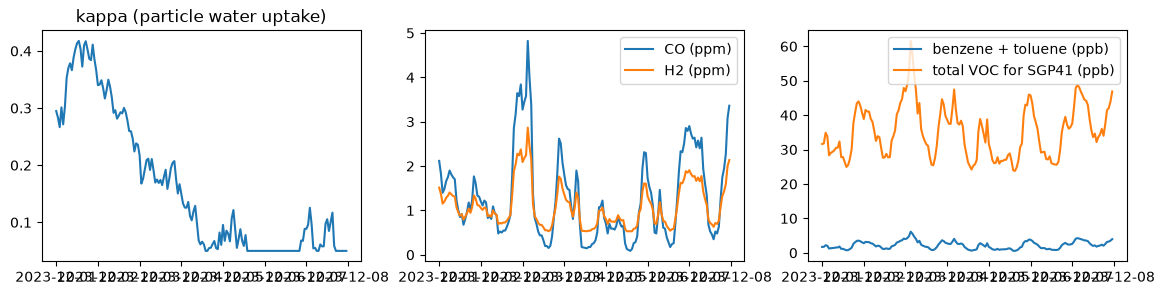

In [4]:
# demo: kappa, and the gases made inside the box (H2 from CO, total VOC from benzene + toluene)
fig, ax = plt.subplots(1, 3, figsize=(14, 3))
ax[0].plot(w_time, w.kappa)
ax[0].set_title("kappa (particle water uptake)")
ax[1].plot(w_time, w.co_ppm, label="CO (ppm)")
ax[1].plot(w_time, w.h2_ppm, label="H2 (ppm)")
ax[1].legend()
ax[2].plot(w_time, w.benzene_ppb + w.toluene_ppb, label="benzene + toluene (ppb)")
ax[2].plot(w_time, w.voc_ppb, label="total VOC for SGP41 (ppb)")
ax[2].legend()
plt.show()

## 2. One formula per sensor

Not every sensor needs the same effort:

| sensor | why it needs a model | kind of model |
|---|---|---|
| PM sensor (SPS30 / PMS7003) | it gives a number, but reads 1.5-2x high in humid Delhi air, misses dust, every unit differs | **full physics model** |
| MQ-7, MQ-135, SGP41 | they give resistance / ticks, not ppm | **full physics model** |
| HDC1080, BMP280 | close to the truth: small bias, sun heating, roof height | thin correction layer |
| 2 wind fans, rain plate | real values: sheltering, start-up speed, 0/1 plate | thin correction layer |
| BH1750 | real lux, but our weather data has sunlight in W/m² | unit conversion |

### 2.1 PM sensor — PMS7003 (fitted now) or SPS30 (later)  (`pm_sensor_params`, `pm_sensor`) — full model
Both are laser-scattering sensors, so they share one formula; only the numbers differ.
Switch in `simulator.py`: `PM_SENSOR = "PMS7003"` (now) or `"SPS30"`; the firmware has the same switch. Three effects:

1. **Humid particles look bigger** (κ-Köhler growth, Crilley 2018). The air inside the sensor is a bit warmer
   ($\Delta T$), which lowers the RH the particles see:
   $$C = 1 + \frac{\kappa/1.65}{1/a_w - 1},\qquad a_w = \min(RH_{inside}/100,\ 0.97)$$
2. **Dust is almost invisible** to the SPS30 (efficiency $e$); dust = part of the coarse mass:
   $$\text{dust}_{2.5} = \min(0.25\,(PM_{10}-PM_{2.5}),\ PM_{2.5}),\qquad \text{fine} = PM_{2.5} - \text{dust}_{2.5}$$
3. **It reads high** (scale $s$); PM10 is mostly guessed from small particles:
   $$PM_{2.5}^{sps} = s\,(\text{fine}\cdot C + e\cdot\text{dust}_{2.5}) + \mathcal{N}(0,\ 0.05x + 1)$$
   $$PM_{10}^{sps} = PM_{2.5}^{sps}(1+q) + s\,f\,(PM_{10}-PM_{2.5}),\qquad PM_{1}^{sps} = r\,s\,\text{fine}\cdot C$$

| parameter | SPS30 | PMS7003 | sources |
|---|---|---|---|
| scale $s$ | U(1.15, 1.55) | U(1.4, 2.0) | IIT-Delhi SPS30 study; EPA PurpleAir (PMS5003) fit ≈ 1.9× |
| inside warming $\Delta T$ | U(1.5, 3.5) °C | U(0, 1) °C | SPS30: needed for field R² ≈ 0.9; PMS: fan-ventilated |
| dust efficiency $e$ | U(0.20, 0.40) | U(0.15, 0.35) | Gautam 2025; Kaur et al. 2026 (PMS underestimates dust) |
| PM10 extrapolation $q$ | U(0.02, 0.10) | U(0.05, 0.20) | Kuula 2020; Macías-Hernández 2023 (PMS PM10 poor) |
| coarse visibility $f$, PM1 ratio $r$ | U(0.05, 0.25), U(0.75, 0.95) | U(0.05, 0.25), U(0.70, 0.90) | Kuula 2020 |
| fog (RH > 95 %) | + U(0, 0.20) | + U(0, 0.25) | spec |

The hygroscopic part ($C$) is the same κ-Köhler correction used for Plantower sensors by Patel et al. 2024;
a dryer study (Brisbane, PMS7003) found drying lowers the reading by 25-40 %. PMS7003 numbers: TODO_VERIFY in Delhi.

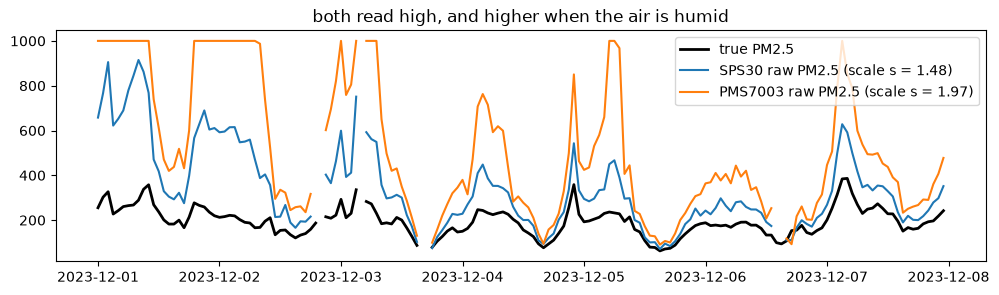

In [5]:
# demo: true PM2.5 vs what one SPS30 and one PMS7003 report
plt.figure(figsize=(12, 3))
plt.plot(w_time, w.pm25, "k", lw=2, label="true PM2.5")
for sensor in ("SPS30", "PMS7003"):
    sim.PM_SENSOR = sensor
    p = sim.pm_sensor_params(rng)
    rh_inside = np.clip(sim.rh_from_dewpoint(w.td, w.t + p["dt_inside"]), 0, 100).to_numpy()
    pm1, pm25, pm10 = sim.pm_sensor(w.pm25.to_numpy(), w.pm10.to_numpy(), rh_inside, w.kappa.to_numpy(), p, rng)
    plt.plot(w_time, pm25, label=f"{sensor} raw PM2.5 (scale s = {p['scale']:.2f})")
sim.PM_SENSOR = "PMS7003"          # back to the sensor on the node
plt.legend()
plt.title("both read high, and higher when the air is humid")
plt.show()

### 2.2 HDC1080 — temperature and humidity  (`hdc1080_params`, `hdc1080`) — thin correction layer
The sun heats the radiation shield, less when the wind cools it (Nakamura & Mahrt 2005):
$$T = T_{true} + b_T + c\,\frac{SW/1000}{1 + k\,ws} + \mathcal{N}(0, 0.3)$$
RH follows from the true dew point at the (warmer) sensor temperature, plus the datasheet error:
$$RH = RH(T_d, T) + b_{RH} + \mathcal{N}(0, 2)$$

| parameter | value | source |
|---|---|---|
| $b_T$ | U(-0.5, 0.5) °C | datasheet |
| $c$ | U(1.0, 2.5) °C per kW/m² | Nakamura & Mahrt |
| $b_{RH}$ | U(-2, 2) % | datasheet |

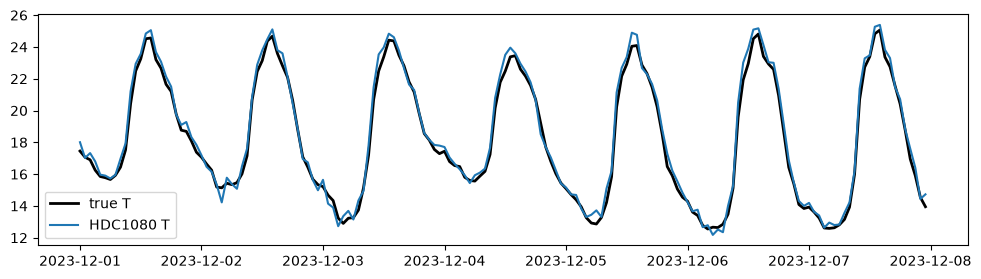

In [6]:
# demo: true vs sensor temperature (look at the daytime bumps from the sun)
p = sim.hdc1080_params(rng)
t, rh = sim.hdc1080(w.t.to_numpy(), w.td.to_numpy(), w.swrad.to_numpy(), 0.7 * w.ws.to_numpy(), p, rng)
plt.figure(figsize=(12, 3))
plt.plot(w_time, w.t, "k", lw=2, label="true T")
plt.plot(w_time, t, label="HDC1080 T")
plt.legend()
plt.show()

### 2.3 BMP280 — pressure  (`bmp280_params`, `bmp280`) — thin correction layer
Pressure drops about 1 hPa per 8.3 m of height (the node sits on a roof):
$$P = P_{true} - \frac{h}{8.3} + b_P + \mathcal{N}(0, 0.1)$$

| $h$ | U(3, 25) m | $b_P$ | U(-1, 1) hPa (datasheet) |
|---|---|---|---|

In [7]:
# demo: the sensor pressure is the true pressure shifted by the roof height
p = sim.bmp280_params(rng)
pressure = sim.bmp280(w.p.to_numpy(), p, rng)
print(f"roof height {p['height']:.1f} m -> mean difference {np.mean(pressure - w.p):.2f} hPa")

roof height 21.5 m -> mean difference -2.77 hPa


### 2.4 Wind: two perpendicular fans  (`wind_params`, `wind_fans`) — thin correction layer
Each fan has a magnet on one blade and ONE hall sensor: the pulse rate gives the wind speed **along that fan's axis**,
but not the sign (one sensor cannot tell which way the fan spins).
Fan 1 points east (x → $u$), fan 2 north (y → $v$). Buildings on the roof shelter the node (factor $k$), the fans are
mounted a few degrees off true north ($\delta$), and a fan does not turn below ~0.3 m/s:
$$u_{fan} = k\,(u\cos\delta - v\sin\delta) + \mathcal{N}(0, 0.2),\qquad v_{fan} = k\,(u\sin\delta + v\cos\delta) + \mathcal{N}(0, 0.2)$$
(each set to 0 if below 0.3 m/s); the node logs $|u_{fan}|$, $|v_{fan}|$ and wind speed $= \sqrt{u_{fan}^2 + v_{fan}^2}$.
The wind DIRECTION the teacher needs comes from the weather data, not from the fans.

| $k$ | U(0.4, 1.0) | $\delta$ | U(-15°, 15°) |
|---|---|---|---|

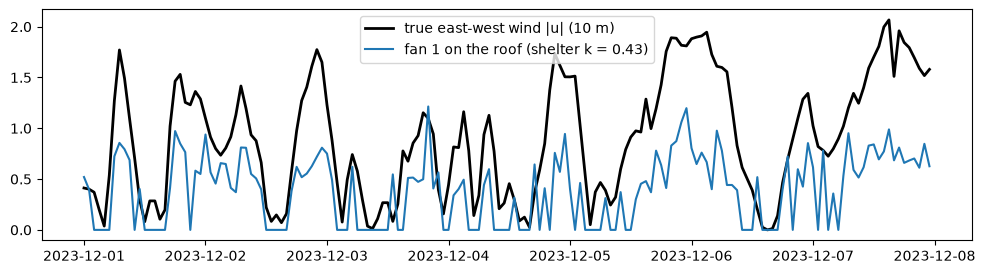

In [8]:
# demo: the east-west fan vs the true east-west wind
p = sim.wind_params(rng)
u_fan, v_fan = sim.wind_fans(w.wind_u.to_numpy(), w.wind_v.to_numpy(), p, rng)
plt.figure(figsize=(12, 3))
plt.plot(w_time, w.wind_u.abs(), "k", lw=2, label="true east-west wind |u| (10 m)")
plt.plot(w_time, u_fan, label=f"fan 1 on the roof (shelter k = {p['shelter']:.2f})")
plt.legend()
plt.show()

### 2.5 Rain plate (digital 0/1)  (`rain_params`, `rain_board`) — thin correction layer
The plate reads 1 (wet) or 0 (dry). The ESP32 reads it every minute and stores the **fraction of the hour it read 1**.
Wet while it rains (> 0.1 mm/h), stays wet while drying for $D$ hours, and dew/fog sometimes wets it
(2 % of hours with RH > 90 %). Fraction of the hour wet:
$$\text{wet} = \begin{cases}1 & \text{raining}\\ \max(0,\ 1 - (h_{since}-1)/D) & \text{otherwise}\end{cases}$$

| $D$ | U(1, 2) h |
|---|---|

In [9]:
# demo: hours the board is wet in the week (December is dry: fog causes most wet hours)
p = sim.rain_params(rng)
wet = sim.rain_board(w.precip.to_numpy(), w.rh.to_numpy(), p, rng)
print(f"raining hours: {(w.precip > 0.1).sum()}, wet board hours: {(wet > 0).sum()}")

raining hours: 0, wet board hours: 2


### 2.6 BH1750 — light  (`bh1750_params`, `bh1750`) — unit conversion
Sunlight (W/m²) times the luminous efficacy (≈ 108 lm/W, Littlefair 1985), dimmed by smog:
$$lux = g \cdot 108 \cdot SW \cdot e^{-\beta\,PM_{2.5}/100} + \mathcal{N}(0, 50),\qquad 0 \text{ at night}$$

| $g$ (mounting/shade) | U(0.6, 1.2) | $\beta$ | U(0, 0.2) |
|---|---|---|---|

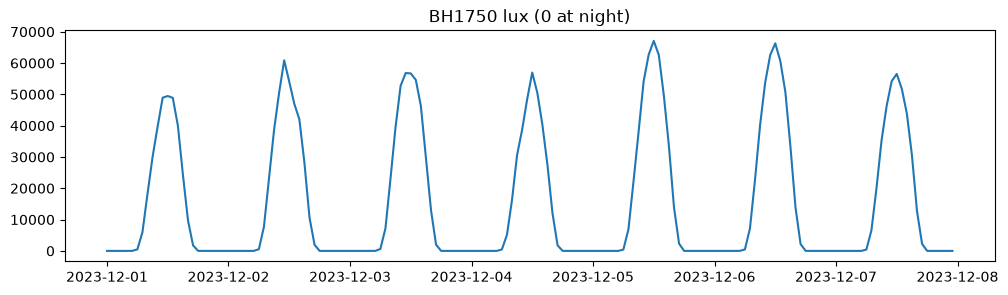

In [10]:
# demo: light follows the sun
p = sim.bh1750_params(rng)
lux = sim.bh1750(w.swrad.to_numpy(), w.pm25.to_numpy(), p, rng)
plt.figure(figsize=(12, 3))
plt.plot(w_time, lux)
plt.title("BH1750 lux (0 at night)")
plt.show()

### 2.7 MQ-7 (CO) and MQ-135 (air quality) — SnO2 chemiresistors  (`mq7`, `mq135`, `mos_resistance`) — full model

**Physics** (Yuan et al. 2022, *Adv. Sci.* — "Modeling interfacial interaction between gas molecules and semiconductor
metal oxides"; Filipovic & Selberherr 2019, *Materials* — thermo-electro-mechanical simulation of MOS sensors):
1. The heater keeps the SnO2 layer hot. Oxygen sits on the surface as $O^-$ and traps electrons → depletion layer → high $R_s$.
2. A reducing gas burns that oxygen and returns the electrons, e.g. $CO + O^-_{ads} \rightarrow CO_2 + e^-$ → $R_s$ falls.
   NO2 is oxidising: it traps more electrons → $R_s$ rises.
3. Adsorption isotherm (Langmuir/Freundlich) → power law $R_s \propto (1 + KC)^{-\beta}$, $\beta \approx 0.5$ for $O^-$.
4. Water also gives electrons ($H_2O + 2Sn + O_{lat} \rightarrow 2\,Sn\text{-}OH + 2e^-$) → $R_s$ falls when humid or warm.
5. Response / recovery times follow Arrhenius laws (seconds to minutes at the heater temperature) → for **hourly** data
   the sensor is in steady state.

$$R_s = R_{air}\left(1 + \frac{\text{gas}}{C_{knee}}\right)^{b}\, e^{\,g_T (T - T_{ref}) + g_{RH}(RH - RH_{ref}) + d\cdot\text{days} + \mathcal{N}(0, 0.03)}$$

**MQ-7 heater cycle** (datasheet): 60 s at 5 V (cleans the surface), then 90 s at 1.4 V (CO sensing); the ESP32 reads
$R_s$ at the end of each low phase → ~24 readings per hour, averaged to one hourly value.

**Which gases each sensor "feels"** (ppm of its reference gas, weights read from the datasheet curves at equal ppm):
- MQ-7: $\text{gas} = CO + w_{H_2} H_2$ — H2 reacts even more strongly than CO (Fig. 3).
- MQ-135: $\text{gas} = H_2 + w_{CO} CO + w_{NH_3} NH_3 + w_{BT}(\text{benzene} + \text{toluene})$, times $(1 + NO_2/20)^{g_{ox}}$.
- H2 is not measured: 0.53 ppm background (Novelli 1999) + traffic H2 ≈ 0.5 × (CO − 0.15) (TODO_VERIFY).

| parameter | MQ-7 (Hanwei) | MQ-135 (Winsen v1.4) | from the datasheet |
|---|---|---|---|
| clean-air resistance $R_{air}$ | 25 × $R_{100}$, $R_{100}$ lognormal over 2-20 kΩ | lognormal, median 27 kΩ | MQ-7 Fig. 3 (air ≈ 25 × R0); MQ-135: Rs(400 ppm H2) 1.2-7 kΩ and Rs(air) ≥ 5 × that |
| knee $C_{knee}$ | U(0.5, 1.1) ppm | U(3, 6) ppm | fitted so the log-log curves match |
| slope $b$ | U(−0.75, −0.55) | U(−0.52, −0.42) | MQ-7: Rs(300)/Rs(100) < 0.5; MQ-135 Fig. 3: −0.40 … −0.48 |
| cross-gas weights | $w_{H_2}$ U(1.2, 1.6) | $w_{NH_3}$ U(0.7, 1.0), $w_{BT}$ U(0.5, 0.8), $w_{CO}$ U(0.1, 0.4), $g_{ox}$ U(0, 0.15) | Fig. 3 at 100 ppm; CO / NO2 for MQ-135: TODO_VERIFY |
| $g_T$ per °C, $g_{RH}$ per %RH | U(−0.009, −0.005), U(−0.004, −0.0015) | U(−0.013, −0.008), U(−0.007, −0.004) | Fig. 4 of each datasheet |
| reference T, RH | 20 °C, 65 % | 20 °C, 55 % | test conditions |
| drift per day | U(−0.0005, 0.0005) | U(−0.001, 0.001) | "long-term stable"; TODO_VERIFY |

In [11]:
# check: a typical MQ-7 against its datasheet curve (Fig. 3, Rs/R0 with R0 = Rs at 100 ppm CO)
typical7 = dict(r_air=25.0, knee_ppm=0.8, b=-0.65, w_h2=1.4, g_t=0, g_rh=0, drift=0)
co = np.array([50, 100, 400, 1000, 4000.0])
rs_over_r0 = typical7["r_air"] * (1 + sim.mq7_gas(co, 0 * co, typical7) / typical7["knee_ppm"]) ** typical7["b"]
print(pd.DataFrame({"CO ppm": co, "model Rs/R0": rs_over_r0.round(2), "datasheet Rs/R0": [1.6, 1.0, 0.4, 0.2, 0.09]}))

   CO ppm  model Rs/R0  datasheet Rs/R0
0    50.0         1.68             1.60
1   100.0         1.08             1.00
2   400.0         0.44             0.40
3  1000.0         0.24             0.20
4  4000.0         0.10             0.09


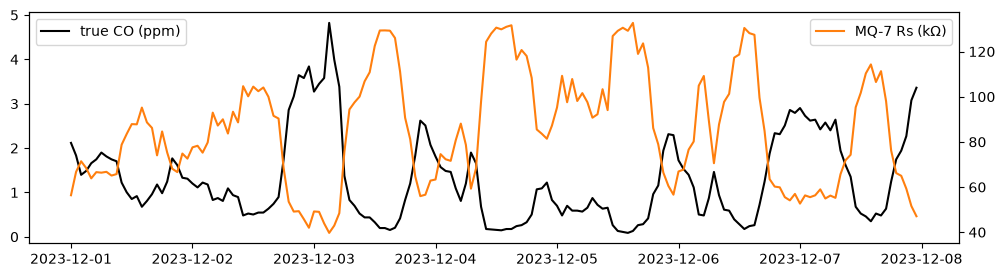

In [12]:
# demo: MQ-7 resistance falls when CO rises
p = sim.mq7_params(rng)
rs = sim.mq7(w.co_ppm.to_numpy(), w.h2_ppm.to_numpy(), w.t.to_numpy(), w.rh.to_numpy(), np.zeros(len(w)), p, rng)
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(w_time, w.co_ppm, "k", label="true CO (ppm)")
ax.legend(loc="upper left")
ax2 = ax.twinx()
ax2.plot(w_time, rs / 1000, color="tab:orange", label="MQ-7 Rs (kΩ)")
ax2.legend(loc="upper right")
plt.show()

**What does the MQ-135 really see in Delhi air?** Its datasheet range is 10-1000 ppm; outdoor NH3 is ~0.05 ppm and
benzene + toluene ~0.006 ppm. Below the knee (a few ppm) the response is almost linear and tiny. The cell below
measures how much each input moves $\ln R_s$ over a whole year of real hourly data (typical unit):

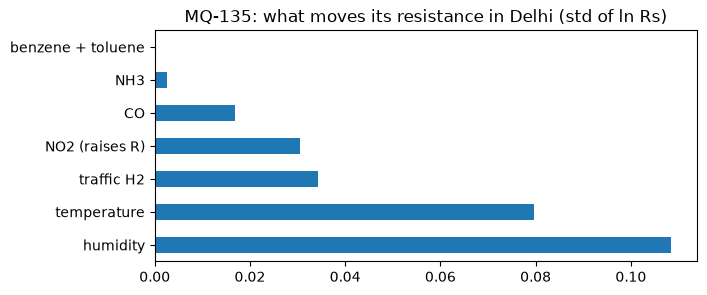

In [13]:
# how much each input moves the MQ-135 resistance (std of ln Rs when only that input varies)
typical135 = dict(r_air=27000, knee_ppm=4.5, b=-0.47, w_nh3=0.85, w_bt=0.65, w_co=0.25, g_ox=0.075,
                  g_t=-0.0105, g_rh=-0.0055, drift=0)
year = truth[(local.dt.year == 2023).to_numpy()]
inputs = {k: year[k].to_numpy(float) for k in ("co_ppm", "h2_ppm", "nh3_ppb", "benzene_ppb", "toluene_ppb", "no2_ppb", "t", "rh")}


def ln_rs135(values):
    gas = sim.mq135_gas(values["co_ppm"], values["h2_ppm"], values["nh3_ppb"], values["benzene_ppb"], values["toluene_ppb"], typical135)
    return (typical135["b"] * np.log1p(gas / typical135["knee_ppm"]) + typical135["g_ox"] * np.log1p(values["no2_ppb"] / 20)
            + typical135["g_t"] * (values["t"] - 20) + typical135["g_rh"] * (values["rh"] - 55))


full = ln_rs135(inputs)
effect = {}
for name, keys in {"humidity": ["rh"], "temperature": ["t"], "traffic H2": ["h2_ppm"], "NO2 (raises R)": ["no2_ppb"],
                   "CO": ["co_ppm"], "NH3": ["nh3_ppb"], "benzene + toluene": ["benzene_ppb", "toluene_ppb"]}.items():
    held = dict(inputs, **{k: np.full_like(inputs[k], np.nanmedian(inputs[k])) for k in keys})
    effect[name] = np.nanstd(full - ln_rs135(held))
pd.Series(effect).plot.barh(title="MQ-135: what moves its resistance in Delhi (std of ln Rs)", figsize=(7, 3))
plt.show()

**Result:** outdoors, the MQ-135 mostly sees **humidity and temperature**, then the **traffic combustion gases**
(H2 + CO, partly cancelled by NO2). NH3 and benzene are far too dilute to matter. So to get the most out of it:
1. the ESP32 removes the typical T/RH effect: $R_c = R_s\,e^{-g_T(T-20) - g_{RH}(RH-55)}$ (datasheet slopes; each unit's
   real slopes differ a bit, so some T/RH effect is left, as on real hardware),
2. the feature is $\ln(R_c / R_{c,base})$ with a 7-day clean-air baseline (removes the unit's own $R_{air}$ and drift),
3. the model also gets T and RH, so it can separate the rest. The same is done for the MQ-7.

**How the ESP32 reads an MQ sensor** (`read_through_adc`, numbers from `pins.h`):
$V_{out} = 5\,V \cdot R_L / (R_s + R_L)$ → 10k/20k divider (× 2/3) → 12-bit ADC → firmware computes
$R_s = R_L (5 - V_{out}) / V_{out}$ with the **nominal** $R_L$ = 10 kΩ. Errors: real $R_L$ ± 5 %, ADC gain ± 2 %,
offset ± 15 mV, noise 5 mV, readable range ~0.05-3.1 V (TODO_VERIFY on the board).

In [14]:
# demo: where the MQ sensors sit on the ESP32 ADC (with RL = 10 kOhm)
p7, p135 = sim.mq7_params(rng), sim.mq135_params(rng)
rs7 = sim.mq7(w.co_ppm.to_numpy(), w.h2_ppm.to_numpy(), w.t.to_numpy(), w.rh.to_numpy(), np.zeros(len(w)), p7, rng)
for name, rs in (("MQ-7", rs7),):
    v_adc = 5 * 10000 / (rs + 10000) * 2 / 3
    print(f"{name}: ADC voltage {v_adc.min():.2f}-{v_adc.max():.2f} V over the week (readable 0.05-3.1 V)")
read_back = sim.read_through_adc(rs7, sim.adc_params(rng), rng)
print(f"MQ-7 resistance error after the ADC: median {np.median(np.abs(read_back / rs7 - 1)):.1%}")

MQ-7: ADC voltage 0.33-1.02 V over the week (readable 0.05-3.1 V)
MQ-7 resistance error after the ADC: median 3.5%


### 2.8 SGP41 — VOC and NOx raw "ticks"  (`sgp41_params`, `sgp41`) — full model

**Physics (metal-oxide gas sensing, e.g. the MOx-mechanism review in Sens. Actuators B 2022 and the RSC 2026
materials review).** The SGP41 has two heated tin-oxide-type (n-type) pixels.
1. Oxygen from the air sits on the hot surface as $O_2^-$ / $O^-$ and pulls electrons out of the oxide →
   an electron-poor **depletion layer** at the grain surface → high resistance.
2. A **reducing** gas (VOCs, CO, H2) reacts with that oxygen and gives the electrons back → resistance **falls**.
   An **oxidising** gas (NO2, O3) takes even more electrons → resistance **rises**.
3. Adsorption follows a Langmuir/Freundlich isotherm, so the resistance follows a power law
   $R = R_0\,(1 + K C)^{\pm\beta}$ (Yamazoe's receptor-transducer model).
4. The SGP41 outputs ticks **proportional to ln R** (datasheet, Table 1 note 3), so
   $$\text{ticks} = B \pm k\,\ln(1 + C / C_0)$$
   i.e. a straight line on a log-concentration axis — exactly the datasheet's Figures 2 and 3.

Response times (VOC < 10 s, NOx < 250 s) are far below one hour, so for hourly data the sensor is in steady state.
The exact Sensirion material is proprietary: this is a **physics-informed behavioural model** fitted to the
datasheet, not a microscopic copy of the chip.

**VOC pixel** (reducing gases lower it; ozone and NO2 push it up, Fig. 2):
$$VOC_{ticks} = B_V - k_V\ln\!\left(1 + \frac{VOC}{100}\right) + a_{O_3}\,O_3 + a_{NO_2}\,NO_2 + \text{drift} + \mathcal{N}(0, 50)$$
**NOx pixel** (oxidising gases raise it — ozone even more than NO2; VOCs lower it slightly, Fig. 3):
$$NOx_{ticks} = B_N + k_{NO_2}\ln\!\left(1+\frac{NO_2}{20}\right) + k_{O_3}\ln\!\left(1+\frac{O_3}{12}\right) - k_{e}\ln\!\left(1+\frac{VOC}{300}\right) + \text{drift} + \mathcal{N}(0, 30)$$

| parameter | value | from the datasheet |
|---|---|---|
| $B_V$, $B_N$ | U(25000, 35000), U(14000, 17000) | typical raw levels |
| $k_V$ | U(1040, 1507) | Table 1: −710…−1030 ticks per doubling of ethanol |
| $a_{O_3}$, $a_{NO_2}$ | U(7, 11), U(2, 3.5) ticks/ppb | Fig. 2 (≈ +850 at 100 ppb O3, ≈ +650 at 300 ppb NO2) |
| $k_{NO_2}$ | U(1500, 3175) | Table 1: +950…+2010 ticks for NO2 150 → 300 ppb |
| $k_{O_3}$ | $k_{NO_2}$ × U(1.25, 1.45) | Fig. 3: the ozone line is ~1.36× steeper |
| knees 20 / 12 ppb | fixed | fitted to Fig. 3 |
| $k_e$ | U(100, 170) | Fig. 3: ethanol line ≈ −310 ticks per decade |
| drift | U(−5, 5) ticks/day | TODO_VERIFY (datasheet only says "low drift") |

Curves were read from the figures by eye → TODO_VERIFY with raw data from a SEK-SGP4x kit.

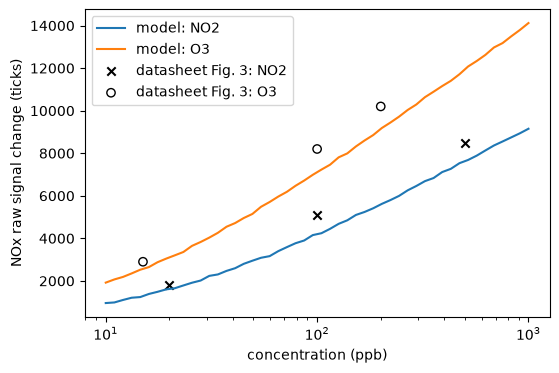

NO2 150 -> 300 ppb: +1549 ticks (datasheet Table 1: typical +1480)


In [15]:
# check: a typical unit's NOx pixel against the datasheet points (Fig. 3) and Table 1
typical = dict(voc_base=0, nox_base=0, voc_k=1255, voc_per_ppb_o3=9, voc_per_ppb_no2=2.7,
               nox_k_no2=2338, nox_k_o3=2338 * 1.36, nox_k_voc=135, drift=0)
calm = np.random.default_rng(0)
conc = np.logspace(1, 3, 50)
zero = np.zeros_like(conc)
_, nox_vs_no2 = sim.sgp41(zero, conc, zero, zero, typical, calm)
_, nox_vs_o3 = sim.sgp41(zero, zero, conc, zero, typical, calm)
plt.figure(figsize=(6, 4))
plt.semilogx(conc, nox_vs_no2, label="model: NO2")
plt.semilogx(conc, nox_vs_o3, label="model: O3")
plt.scatter([20, 100, 500], [1800, 5100, 8500], marker="x", c="k", label="datasheet Fig. 3: NO2")
plt.scatter([15, 100, 200], [2900, 8200, 10200], marker="o", facecolors="none", edgecolors="k", label="datasheet Fig. 3: O3")
plt.xlabel("concentration (ppb)")
plt.ylabel("NOx raw signal change (ticks)")
plt.legend()
plt.show()
_, two = sim.sgp41(np.zeros(2), np.array([150.0, 300.0]), np.zeros(2), np.zeros(2), typical, calm)
print(f"NO2 150 -> 300 ppb: {two[1] - two[0]:+.0f} ticks (datasheet Table 1: typical +1480)")

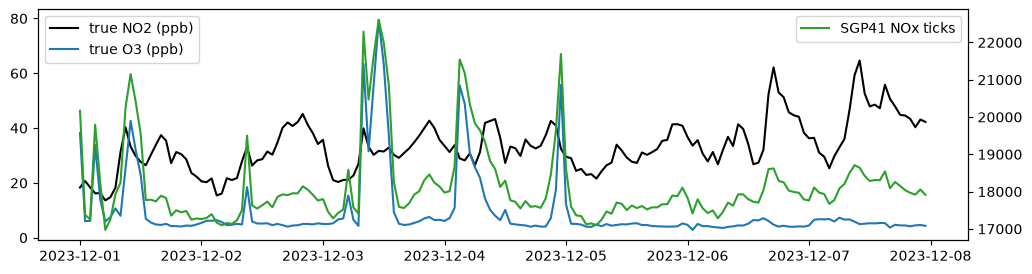

In [16]:
# demo: NOx ticks follow NO2 AND ozone (Delhi's afternoon ozone gives the midday peaks)
p = sim.sgp41_params(rng)
voc, nox = sim.sgp41(w.voc_ppb.to_numpy(), w.no2_ppb.to_numpy(), w.o3_ppb.to_numpy(), np.zeros(len(w)), p, rng)
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(w_time, w.no2_ppb, "k", label="true NO2 (ppb)")
ax.plot(w_time, w.o3_ppb, "tab:blue", label="true O3 (ppb)")
ax.legend(loc="upper left")
ax2 = ax.twinx()
ax2.plot(w_time, nox, color="tab:green", label="SGP41 NOx ticks")
ax2.legend(loc="upper right")
plt.show()

**On the ESP32: Sensirion's Gas Index Algorithm** (`gas_index`). The node runs Sensirion's official open-source
library on the raw ticks. It learns the usual level of the last ~12 hours (mean and spread) and maps the signal to:
- **VOC Index** 1-500: 100 = the usual air of the last days, > 100 = worse, < 100 = better;
- **NOx Index** 1-500: 1 = usual, > 1 = an NOx event.

We call the same library (`sensirion-gas-index-algorithm`, BSD-3) with a 3600 s sampling interval because our
data is hourly (its learning times are given in hours, so they stay the same).
The model features still use the raw ticks against their 7-day baseline (`voc_n`, `nox_n`) because the NOx Index
sits at 1 most of the time and throws information away; the indices are kept in Y for the dashboard and firmware tests.

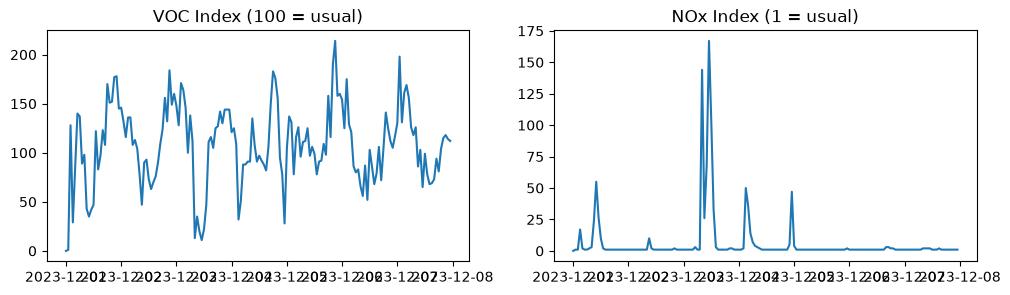

In [17]:
# demo: the raw ticks of the week -> VOC and NOx Index
voc_index, nox_index = sim.gas_index(voc, nox)
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
ax[0].plot(w_time, voc_index)
ax[0].set_title("VOC Index (100 = usual)")
ax[1].plot(w_time, nox_index)
ax[1].set_title("NOx Index (1 = usual)")
plt.show()

### 2.9 Sensor faults  (`sps30_faults`)
Each hour has a 1 % chance of a missing PM reading, and about once a year the SPS30 is down for U(6, 48) hours.
(Hours where CPCB itself has no PM are simply missing — that is not a sensor fault.)

In [18]:
# demo: faults over one simulated year
missing, outage = sim.sps30_faults(8766, rng)
print(f"random missing hours: {missing.sum()}, outage hours: {outage.sum()}")

random missing hours: 110, outage hours: 42


## 3. What the ESP32 does every hour  (`process_on_device`)

| step | formula |
|---|---|
| humidity correction of PM | $PM_{corr} = PM_{sps} / C(RH, \kappa = 0.4)$ (fixed κ until we calibrate on site) |
| coarse ratio | $(PM_{10}-PM_{2.5}) / \max(PM_1, 1)$ |
| dust flag | coarse ratio > 0.5 and RH < 60 % |
| MQ T/RH compensation | $R_c = R_s\,e^{-g_T(T-20) - g_{RH}(RH-RH_{ref})}$ with the datasheets' typical slopes |
| gas baselines | clean-air level = 90 % quantile of the last 7 days (NOx: 10 %) |
| VOC / NOx Index | Sensirion Gas Index Algorithm on the SGP41 ticks (section 2.8) |
| PM state | ok / filled (1 h hole) / Model B fallback (≤ 24 h) / unavailable |
| CPCB AQI | from 24-h means, needs ≥ 16 measured hours |

**CPCB AQI** (India): each pollutant's 24-h mean is mapped linearly inside its band, AQI = the larger sub-index.

| AQI band | 0-50 | 51-100 | 101-200 | 201-300 | 301-400 | 401-500 |
|---|---|---|---|---|---|---|
| PM2.5 (µg/m³) | 0-30 | 31-60 | 61-90 | 91-120 | 121-250 | 250+ |
| PM10 (µg/m³) | 0-50 | 51-100 | 101-250 | 251-350 | 351-430 | 430+ |

$$I = I_{lo} + \frac{I_{hi} - I_{lo}}{B_{hi} - B_{lo}}(C - B_{lo})$$

Breakpoints checked against the official CPCB NAQI table (`docs/cpcb_aqi_breakpoints.png`). Our two choices: a band
starts where the previous one ended (so 30.5 µg/m³ is not "between" bands), and the open "Severe" band runs to
380 (PM2.5) / 510 (PM10) as in CPCB's AQI calculator; anything above is AQI 500.

In [19]:
# demo: a few AQI values
for pm in (25, 45, 75, 180, 300):
    print(f"PM2.5 24-h mean {pm:4d} ug/m3 -> sub-index {sim.sub_index(pm, sim.PM25_LIMITS):.0f}")

PM2.5 24-h mean   25 ug/m3 -> sub-index 42
PM2.5 24-h mean   45 ug/m3 -> sub-index 76
PM2.5 24-h mean   75 ug/m3 -> sub-index 150
PM2.5 24-h mean  180 ug/m3 -> sub-index 347
PM2.5 24-h mean  300 ug/m3 -> sub-index 439


## 4. The whole box on the demo station: X → Y  (`simulate`)

In [20]:
# run the box for unit 0 of the demo station and look at a few hours of Y
Y = sim.simulate(X, DEMO_STATION, unit=0, network_typical=own_typical)
Y[week].head()

,ts,pm1,pm25,pm10,t,rh,p,wind_u,wind_v,wind_speed,...,Rbase7,Rbase135,base_voc,base_nox,voc_index,nox_index,aqi_pm,sim_outage,true_pm25,true_pm10
51840,2023-11-30 18:30:00+00:00,1000.0,1000.0,1000.0,17.363690,97.091699,992.573539,0.303856,1.444052,1.475675,...,27751.765907,6301.660642,28522.2,18315.2,46.0,42.0,387.0,False,255.25,439.75
51841,2023-11-30 19:30:00+00:00,1000.0,1000.0,1000.0,16.983108,97.865147,992.228648,0.386194,1.279212,1.336237,...,27751.765907,6301.660642,28522.2,18315.2,97.0,3.0,387.0,False,302.50,482.25
51842,2023-11-30 20:30:00+00:00,1000.0,1000.0,1000.0,16.492830,96.865230,992.397692,0.000000,1.294182,1.294182,...,27751.765907,6301.660642,28522.2,18315.2,111.0,1.0,387.0,False,326.75,500.75
51843,2023-11-30 21:30:00+00:00,1000.0,1000.0,1000.0,15.938780,100.000000,992.059376,0.000000,1.577086,1.577086,...,27751.765907,6301.660642,28522.2,18315.2,57.0,22.0,387.0,False,227.25,364.50
51844,2023-11-30 22:30:00+00:00,1000.0,1000.0,1000.0,15.452960,100.000000,991.923149,0.000000,1.192600,1.192600,...,27751.765907,6301.660642,28522.2,18315.2,103.0,3.0,387.0,False,242.50,396.00


## 5. Run it for every station

In [21]:
# load the clean tables; keep stations with at least one year (8760 h) of BOTH PM2.5 and PM10
# (the SPS30 formula and the targets need both; Sector 16A Faridabad has no PM10)
clean = {p.stem: pd.read_parquet(p) for p in sorted(CLEAN.glob("*.parquet"))}
stations = [s for s, df in clean.items() if (df.pm25.notna() & df.pm10.notna()).sum() >= 8760]
print(len(stations), "stations; dropped:", sorted(set(clean) - set(stations)))

32 stations; dropped: ['sector_16a_faridabad_hspcb']


In [22]:
# typical gas level per (month, IST hour) over all stations: fallback for stations without a gas
all_clean = pd.concat(clean[s] for s in stations)
local_all = all_clean.ts.dt.tz_convert("Asia/Kolkata")
network_typical = {g: all_clean[g].groupby([local_all.dt.month, local_all.dt.hour]).median() for g in sim.GASES}
del all_clean

In [23]:
# simulate 3 units per station and save them (skips files that already exist)
unit_table = []
for station in stations:
    for unit in range(UNITS_PER_STATION):
        path = OUT / f"{station}_u{unit}.parquet"
        if not path.exists():
            sim.simulate(clean[station], station, unit, network_typical).to_parquet(path, index=False)
        params = sim.draw_unit(sim.make_rng(station, unit))           # this unit's errors (same every run)
        unit_table.append({"station": station, "unit": unit,
                           **{f"{s}.{k}": round(v, 4) for s, d in params.items() for k, v in d.items()}})
pd.DataFrame(unit_table).to_csv(OUT / "units.csv", index=False)
print(len(unit_table), "virtual units")

96 virtual units


## 6. Is it realistic?
**PM sensor vs reference in Delhi winter.** IIT-Delhi SPS30 field study (Kumar et al. 2025): slope 1.46-1.86, R² ≈ 0.91.
We undo the device correction and fit raw SPS30 PM2.5 against true PM2.5 for every unit.

In [24]:
# slope and R2 of raw SPS30 vs true PM2.5 in winter, per unit
def winter_fit(rec):
    winter = rec.ts.dt.tz_convert("Asia/Kolkata").dt.month.isin([11, 12, 1, 2])
    raw = rec.pm25_corr * (1 + (0.4 / 1.65) / (1 / np.clip(rec.rh / 100, 1e-9, 0.95) - 1))
    ok = winter & rec.pm_state.eq("ok") & raw.notna() & rec.true_pm25.notna()
    slope = np.polyfit(rec.true_pm25[ok], raw[ok], 1)[0]
    r2 = np.corrcoef(rec.true_pm25[ok], raw[ok])[0, 1] ** 2
    return slope, r2


fits = pd.DataFrame([winter_fit(pd.read_parquet(p)) for p in sorted(OUT.glob("*_u*.parquet"))], columns=["slope", "r2"])
fits.describe().round(2)

,slope,r2
count,96.00,96.00
mean,2.22,0.61
std,0.15,0.07
min,1.94,0.46
25%,2.11,0.56
50%,2.19,0.61
75%,2.36,0.67
max,2.63,0.74


In [25]:
# check: for the SPS30 the median slope must be inside the IIT-Delhi range
print(f"{sim.PM_SENSOR}: median slope {fits.slope.median():.2f}, median R2 {fits.r2.median():.2f}, "
      f"units inside 1.46-1.86: {fits.slope.between(1.46, 1.86).mean():.0%}")
if sim.PM_SENSOR == "SPS30":
    assert 1.46 <= fits.slope.median() <= 1.86

PMS7003: median slope 2.19, median R2 0.61, units inside 1.46-1.86: 0%


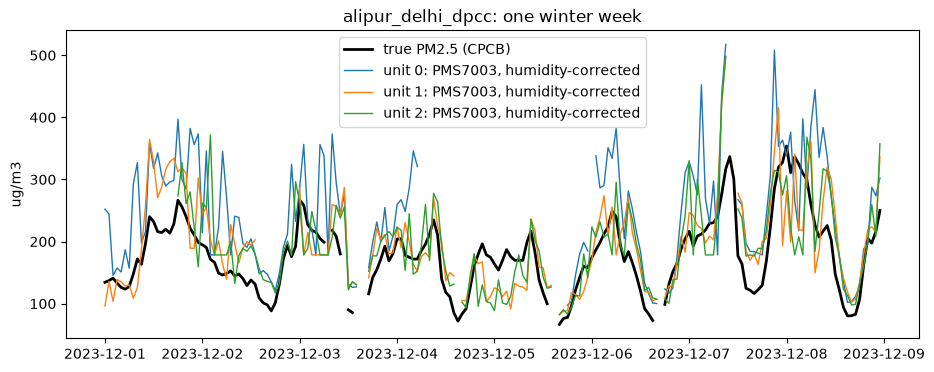

In [26]:
# one winter week: true PM2.5 vs what the 3 units of one station report
station = stations[0]
plt.figure(figsize=(11, 4))
for unit in range(3):
    rec = pd.read_parquet(OUT / f"{station}_u{unit}.parquet").set_index("ts").tz_convert("Asia/Kolkata").loc["2023-12-01":"2023-12-08"]
    if unit == 0:
        plt.plot(rec.index, rec.true_pm25, "k", lw=2, label="true PM2.5 (CPCB)")
    plt.plot(rec.index, rec.pm25_corr, lw=1, label=f"unit {unit}: {sim.PM_SENSOR}, humidity-corrected")
plt.title(f"{station}: one winter week")
plt.ylabel("ug/m3")
plt.legend()
plt.show()

In [27]:
# do the gas sensors follow their gas? (correlation with the true value at one station)
rec = pd.read_parquet(OUT / f"{station}_u0.parquet").merge(clean[station][["ts", "co_ppm", "no2_ppb", "o3_ppb", "swrad"]], on="ts")
checks = {"MQ-7 ln(Rc/Rbase) vs ln CO": (np.log(rec.mq7_rc / rec.Rbase7), np.log(rec.co_ppm.clip(lower=0.05))),
          "MQ-135 ln(Rc/Rbase) vs ln CO": (np.log(rec.mq135_rc / rec.Rbase135), np.log(rec.co_ppm.clip(lower=0.05))),
          "SGP41 NOx vs NO2+O3": (rec.sraw_nox - rec.base_nox, np.log1p((rec.no2_ppb + 3.5 * rec.o3_ppb) / 10)),
          "BH1750 vs sunshine": (np.log1p(rec.lux), rec.swrad)}
for name, (a, b) in checks.items():
    both = pd.DataFrame({"a": a, "b": b}).replace([np.inf, -np.inf], np.nan).dropna()
    print(f"{name:30s} r = {both.a.corr(both.b):+.2f}")

MQ-7 ln(Rc/Rbase) vs ln CO     r = -0.77
MQ-135 ln(Rc/Rbase) vs ln CO   r = -0.26
SGP41 NOx vs NO2+O3            r = +0.90
BH1750 vs sunshine             r = +0.79
